# 基于异常收益的注意力捕捉

**行为金融因子 —— 投资者注意力**

对每个行业，分别统计每日行业内成分股中收益率绝对值高于 7% 的股票数量占比，作为市场关注程度的代理指标：

$$
\text{indus_abnd}_d = \frac{n_{\ge 7\%, d}}{N_d}
$$

其中，$n_{\ge 7\%, d}$ 为行业成分股中当日收益率绝对值达到或超过 7% 的股票数量，$N_d$ 为该行业当日交易股票总数。

进一步，将上述市场关注代理指标与个股日收益进行月度时序回归，回归方程如下：

$$
r_{i,d} = \mu_{i,t} + \beta_{i,t} \cdot \text{indus_abnd}_d + \rho_{1,i,t} \text{Mkt}_d + \rho_{2,i,t} \text{SMB}_d + \rho_{3,i,t} \text{HML}_d + \rho_{4,i,t} \text{UMD}_d + \epsilon_{i,t}
$$

其中，系数 $\beta_{i,t}$ 的绝对值 $|\beta_{i,t}|$ 即为股票 $i$ 对市场关注程度的敏感度，用于衡量该股票受投资者注意力影响的大小。

各变量定义如下：

* $r_{i,d}$ 为股票 $i$ 在交易日 $d$ 的收益率；
* $\text{Mkt}_d$、$\text{SMB}_d$、$\text{HML}_d$ 分别为经典的 Fama‑French 三因子在 $d$ 日的收益；
* $\text{UMD}_d$ 为动量因子收益，即全市场过去 11 个月累积收益率排名前 30% 与后 30% 的股票组合在 $d$ 日的收益差；
* $\mu_{i,t}$ 为截距项，$\epsilon_{i,t}$ 为残差项。

## 因子逻辑说明

不同股票对同一市场关注度事件的反映程度往往不同，可通过个股收益对市场关注度事件的敏感程度（即 $|\beta_{i,t}|$）来衡量股票对该事件的注意力捕捉效应。捕捉能力越强（敏感程度越高），表明该股票更能吸引市场注意，从而引发更多的买盘压力，导致股价被高估。

上述因子以异常收益占比（收益率绝对值超过 7% 的股票比例）作为市场关注度事件，其原因在于：极端日收益是衡量关注度的一个重要指标，出现过高或过低的收益都代表着该股票或行业受到了投资者的广泛关注。因此，该指标能够有效捕捉投资者注意力的集中程度，并进一步用于解释个股收益的横截面差异。

数据：日度收盘价、Fama-French因子（市值、无风险收益率、账面市值比（净资产/总市值））、行业分类数据

In [3]:
import numpy as np
import pandas as pd

from rqdatac import (
    all_instruments,
    get_factor,
    get_instrument_industry,
    get_price,
    get_trading_dates,
)


# ============================================================
# 1. 通用数据处理函数
# ============================================================

def _ac_chunks(items, batch_size):
    for start in range(0, len(items), batch_size):
        yield items[start:start + batch_size]


def _ac_to_wide(raw, order_book_ids, dates, value_col):
    """
    将米筐返回的长表 / MultiIndex 表转换为：
    index=date, columns=order_book_id 的宽表。
    """
    if raw is None or len(raw) == 0:
        return pd.DataFrame(index=dates, columns=order_book_ids, dtype=float)

    if isinstance(raw, pd.Series):
        raw = raw.to_frame(name=value_col)

    data = raw.copy()

    if isinstance(data.index, pd.MultiIndex) or data.index.name is not None:
        data = data.reset_index()

    if "order_book_id" not in data.columns:
        candidates = [
            col for col in data.columns
            if col.lower() in ("instrument", "symbol", "order_book_id")
        ]
        if not candidates:
            raise ValueError("无法在返回数据中识别 order_book_id 字段。")
        data = data.rename(columns={candidates[0]: "order_book_id"})

    if "date" not in data.columns:
        candidates = [
            col for col in data.columns
            if col.lower() in ("datetime", "trading_date", "date")
        ]
        if not candidates:
            raise ValueError("无法在返回数据中识别 date 字段。")
        data = data.rename(columns={candidates[0]: "date"})

    if value_col not in data.columns:
        non_key_cols = [
            col for col in data.columns
            if col not in ("date", "order_book_id")
        ]
        if len(non_key_cols) != 1:
            raise ValueError(
                "无法识别数值列 {}，当前列为：{}".format(
                    value_col, list(data.columns)
                )
            )
        data = data.rename(columns={non_key_cols[0]: value_col})

    data["date"] = pd.to_datetime(data["date"])

    wide = data.pivot_table(
        index="date",
        columns="order_book_id",
        values=value_col,
        aggfunc="last",
    )

    return wide.reindex(index=dates, columns=order_book_ids)


def _ac_get_price_wide(order_book_ids, dates, fields, batch_size):
    """分批下载日线数据，并转为宽表字典。"""
    result = {field: [] for field in fields}

    for ids in _ac_chunks(order_book_ids, batch_size):
        raw = get_price(
            order_book_ids=ids,
            start_date=dates[0],
            end_date=dates[-1],
            frequency="1d",
            fields=fields,
            adjust_type="pre",
            skip_suspended=False,
            expect_df=True,
        )

        for field in fields:
            result[field].append(
                _ac_to_wide(raw, ids, dates, field)
            )

    output = {}
    for field in fields:
        output[field] = (
            pd.concat(result[field], axis=1)
            .reindex(index=dates, columns=order_book_ids)
        )

    return output


def _ac_get_factor_wide(
    order_book_ids,
    dates,
    factor_name,
    batch_size,
):
    """分批下载 get_factor 数据。"""
    blocks = []

    for ids in _ac_chunks(order_book_ids, batch_size):
        raw = get_factor(
            order_book_ids=ids,
            factor=factor_name,
            start_date=dates[0],
            end_date=dates[-1],
            expect_df=True,
        )

        blocks.append(
            _ac_to_wide(raw, ids, dates, factor_name)
        )

    return (
        pd.concat(blocks, axis=1)
        .reindex(index=dates, columns=order_book_ids)
        .astype(float)
    )


def _ac_get_industry_codes(
    order_book_ids,
    date,
    industry_source,
    industry_level,
    batch_size,
):
    """
    获取某一日期的行业编码。
    返回 Series：
    index=order_book_id，value=行业代码。
    """
    blocks = []

    if industry_level != 1:
        raise ValueError("当前函数仅实现中信一级行业，请设置 industry_level=1。")

    industry_field = "first_industry_code"

    for ids in _ac_chunks(order_book_ids, batch_size):
        raw = get_instrument_industry(
            order_book_ids=ids,
            source=industry_source,
            level=industry_level,
            date=date,
        )

        if raw is None or len(raw) == 0:
            continue

        data = raw.copy()

        if isinstance(data.index, pd.MultiIndex) or data.index.name is not None:
            data = data.reset_index()

        if "order_book_id" not in data.columns:
            possible_cols = [
                col for col in data.columns
                if col.lower() in ("instrument", "symbol", "order_book_id")
            ]
            if not possible_cols:
                raise ValueError("行业数据中无法识别 order_book_id。")
            data = data.rename(columns={possible_cols[0]: "order_book_id"})

        if industry_field not in data.columns:
            raise ValueError(
                "行业数据中不存在字段 {}，当前列为：{}".format(
                    industry_field, list(data.columns)
                )
            )

        blocks.append(
            data.set_index("order_book_id")[industry_field]
        )

    if not blocks:
        return pd.Series(dtype=object)

    return pd.concat(blocks).groupby(level=0).last()


def _ac_first_dates_by_month(dates):
    """每个月的第一个交易日。"""
    month_index = dates.to_period("M")
    return dates[~month_index.duplicated()]


def _ac_first_dates_by_july(dates):
    """每年 7 月的第一个交易日。"""
    month_first_dates = _ac_first_dates_by_month(dates)
    return month_first_dates[month_first_dates.month == 7]


def _ac_value_weighted_return(returns, weights, mask, min_stocks):
    """计算一个组合的市值加权收益。"""
    valid = (
        mask
        & np.isfinite(returns)
        & np.isfinite(weights)
        & (weights > 0)
    )

    if valid.sum() < min_stocks:
        return np.nan

    selected_weights = weights[valid]
    selected_returns = returns[valid]

    return np.dot(selected_returns, selected_weights) / selected_weights.sum()


# ============================================================
# 2. 构造 MKT / SMB / HML / UMD
# ============================================================

def _ac_safe_size_value_masks(
    cap,
    btm,
    valid,
    size_breakpoint,
    btm_low,
    btm_high,
):
    """仅对有效股票做 Size / BTM 分组，避免 NaN 比较警告。"""
    n_stocks = len(cap)

    small = np.zeros(n_stocks, dtype=bool)
    big = np.zeros(n_stocks, dtype=bool)

    low = np.zeros(n_stocks, dtype=bool)
    neutral = np.zeros(n_stocks, dtype=bool)
    high = np.zeros(n_stocks, dtype=bool)

    valid_idx = np.flatnonzero(valid)

    cap_valid = cap[valid_idx]
    btm_valid = btm[valid_idx]

    small[valid_idx] = cap_valid <= size_breakpoint
    big[valid_idx] = cap_valid > size_breakpoint

    low[valid_idx] = btm_valid <= btm_low
    neutral[valid_idx] = (
        (btm_valid > btm_low)
        & (btm_valid <= btm_high)
    )
    high[valid_idx] = btm_valid > btm_high

    return small, big, low, neutral, high

def _ac_safe_momentum_masks(
    cumulative_return,
    valid,
    loser_breakpoint,
    winner_breakpoint,
):
    """仅对有效股票做动量分组，避免 NaN 比较警告。"""
    n_stocks = len(cumulative_return)

    losers = np.zeros(n_stocks, dtype=bool)
    winners = np.zeros(n_stocks, dtype=bool)

    valid_idx = np.flatnonzero(valid)
    valid_return = cumulative_return[valid_idx]

    losers[valid_idx] = valid_return <= loser_breakpoint
    winners[valid_idx] = valid_return >= winner_breakpoint

    return losers, winners

def _ac_build_ff4_controls(
    returns,
    lag_market_cap,
    lag_book_to_market,
    min_market_stocks=100,
    min_portfolio_stocks=10,
):
    """
    构造日频 MKT / SMB / HML / UMD。

    MKT:
        全市场前一日市值加权日收益，不减无风险利率。

    SMB / HML:
        每年 7 月首个交易日，按前一日市值和 B/M 分为：
        Small/Big × Low/Neutral/High，共六个组合；
        持有至下一年 7 月。

    UMD:
        每月首个交易日，以过去 11 个完整自然月的累计收益排序，
        跳过最近一个月，取前 30% 与后 30%，持有一个月。
    """
    dates = returns.index
    return_array = returns.values.astype(float)
    cap_array = lag_market_cap.values.astype(float)
    btm_array = lag_book_to_market.values.astype(float)

    n_dates, n_stocks = return_array.shape

    # --------------------------------------------------------
    # SMB / HML：每年 7 月形成一次 2 × 3 组合
    # --------------------------------------------------------
    size_label = np.full((n_dates, n_stocks), -1, dtype=np.int8)
    value_label = np.full((n_dates, n_stocks), -1, dtype=np.int8)

    annual_rebalance_dates = _ac_first_dates_by_july(dates)
    annual_positions = [dates.get_loc(date) for date in annual_rebalance_dates]

    for seq, position in enumerate(annual_positions):
        end_position = (
            annual_positions[seq + 1]
            if seq + 1 < len(annual_positions)
            else n_dates
        )

        cap = cap_array[position]
        btm = btm_array[position]

        valid = (
            np.isfinite(cap)
            & np.isfinite(btm)
            & (cap > 0)
            & (btm > 0)
        )

        if valid.sum() < max(min_market_stocks, 30):
            continue

        size_breakpoint = np.median(cap[valid])
        btm_low, btm_high = np.percentile(
            btm[valid],
            [30.0, 70.0],
        )

        small, big, low, neutral, high = _ac_safe_size_value_masks(
            cap=cap,
            btm=btm,
            valid=valid,
            size_breakpoint=size_breakpoint,
            btm_low=btm_low,
            btm_high=btm_high,
        )

        size_label[position:end_position, small] = 0
        size_label[position:end_position, big] = 1

        value_label[position:end_position, low] = 0
        value_label[position:end_position, neutral] = 1
        value_label[position:end_position, high] = 2

    # --------------------------------------------------------
    # UMD：每月形成一次，过去 11 个月、跳过最近 1 个月
    # --------------------------------------------------------
    momentum_label = np.full((n_dates, n_stocks), -1, dtype=np.int8)

    month_periods = dates.to_period("M")
    monthly_rebalance_dates = _ac_first_dates_by_month(dates)
    monthly_positions = [dates.get_loc(date) for date in monthly_rebalance_dates]

    for seq, position in enumerate(monthly_positions):
        end_position = (
            monthly_positions[seq + 1]
            if seq + 1 < len(monthly_positions)
            else n_dates
        )

        current_month = dates[position].to_period("M")

        # t-12 月至 t-2 月：共 11 个完整自然月
        begin_month = current_month - 12
        finish_month = current_month - 2

        history_mask = (
            (month_periods >= begin_month)
            & (month_periods <= finish_month)
        )

        history_returns = return_array[history_mask]

        if history_returns.shape[0] < 150:
            continue

        # 要求整个动量观察期内存在连续、可交易收益
        valid_history = np.isfinite(history_returns).all(axis=0)

        cumulative_return = np.full(n_stocks, np.nan)
        cumulative_return[valid_history] = (
            np.prod(
                1.0 + history_returns[:, valid_history],
                axis=0,
            ) - 1.0
        )

        formation_cap = cap_array[position]

        valid = (
            valid_history
            & np.isfinite(cumulative_return)
            & np.isfinite(formation_cap)
            & (formation_cap > 0)
        )

        if valid.sum() < max(min_market_stocks, 30):
            continue

        loser_breakpoint, winner_breakpoint = np.percentile(
            cumulative_return[valid],
            [30.0, 70.0],
        )

        losers, winners = _ac_safe_momentum_masks(
            cumulative_return=cumulative_return,
            valid=valid,
            loser_breakpoint=loser_breakpoint,
            winner_breakpoint=winner_breakpoint,
        )

        momentum_label[position:end_position, losers] = 0
        momentum_label[position:end_position, winners] = 1

    # --------------------------------------------------------
    # 每日组合收益
    # --------------------------------------------------------
    factor_values = np.full((n_dates, 4), np.nan)

    for t in range(n_dates):
        daily_return = return_array[t]
        daily_cap = cap_array[t]

        # MKT：全市场市值加权收益
        market_mask = (
            np.isfinite(daily_return)
            & np.isfinite(daily_cap)
            & (daily_cap > 0)
        )

        factor_values[t, 0] = _ac_value_weighted_return(
            daily_return,
            daily_cap,
            market_mask,
            min_market_stocks,
        )

        # SMB / HML：六个 Size × B/M 组合
        portfolio_returns = {}

        for size in (0, 1):
            for value in (0, 1, 2):
                mask = (
                    (size_label[t] == size)
                    & (value_label[t] == value)
                )

                portfolio_returns[(size, value)] = _ac_value_weighted_return(
                    daily_return,
                    daily_cap,
                    mask,
                    min_portfolio_stocks,
                )

        sl = portfolio_returns[(0, 0)]
        sn = portfolio_returns[(0, 1)]
        sh = portfolio_returns[(0, 2)]

        bl = portfolio_returns[(1, 0)]
        bn = portfolio_returns[(1, 1)]
        bh = portfolio_returns[(1, 2)]

        if np.isfinite([sl, sn, sh, bl, bn, bh]).all():
            factor_values[t, 1] = (
                (sl + sn + sh) / 3.0
                - (bl + bn + bh) / 3.0
            )

            factor_values[t, 2] = (
                (sh + bh) / 2.0
                - (sl + bl) / 2.0
            )

        # UMD：前 30% 动量组合 - 后 30% 动量组合
        winner_return = _ac_value_weighted_return(
            daily_return,
            daily_cap,
            momentum_label[t] == 1,
            min_portfolio_stocks,
        )

        loser_return = _ac_value_weighted_return(
            daily_return,
            daily_cap,
            momentum_label[t] == 0,
            min_portfolio_stocks,
        )

        if np.isfinite(winner_return) and np.isfinite(loser_return):
            factor_values[t, 3] = winner_return - loser_return

    return pd.DataFrame(
        factor_values,
        index=dates,
        columns=["MKT", "SMB", "HML", "UMD"],
    )


# ============================================================
# 3. 构造行业异常收益注意力，并进行滚动回归
# ============================================================

def calculate_indus_abnd_attention_daily(
    start_date,
    end_date,
    candidate_ids=None,
    universe_ids=None,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    abnormal_threshold=0.07,
    regression_window=20,
    min_industry_stocks=5,
    min_market_stocks=100,
    min_portfolio_stocks=10,
    initial_lookback_calendar_days=900,
    price_batch_size=500,
    industry_batch_size=2000,
    return_controls=False,
):
    """
    基于异常收益的注意力捕捉因子。

    返回
    ----
    DataFrame
        两层 MultiIndex：
        date, order_book_id

        列：
        INDUS_ABND_BETA

        数值为滚动回归中行业注意力变量 beta 的绝对值。

    参数说明
    --------
    candidate_ids:
        最终需要输出因子的股票；None 表示全 A 股。

    universe_ids:
        构造行业注意力、MKT、SMB、HML、UMD 时使用的股票池；
        None 表示全 A 股。正式回测建议保持 None。

    industry_refresh:
        "M"：每月首个交易日更新行业归属，推荐；
        "D"：每日更新，最精确但请求量很大。

    return_controls:
        True 时，返回 (factor, controls)；
        controls 为日频 MKT / SMB / HML / UMD。
    """
    if regression_window <= 6:
        raise ValueError(
            "regression_window 必须大于 6，"
            "因为回归中包含截距、行业注意力和四个控制变量。"
        )

    if industry_refresh not in ("M", "D"):
        raise ValueError('industry_refresh 仅支持 "M" 或 "D"。')

    # --------------------------------------------------------
    # 股票池
    # --------------------------------------------------------
    all_stock_ids = list(
        all_instruments("CS")["order_book_id"].dropna().unique()
    )

    if universe_ids is None:
        universe_ids = all_stock_ids
    else:
        universe_ids = list(pd.Index(universe_ids).dropna().unique())

    if candidate_ids is None:
        candidate_ids = universe_ids
    else:
        candidate_ids = list(pd.Index(candidate_ids).dropna().unique())

    # 保证待输出股票也在因子构造股票池中
    total_ids = list(
        dict.fromkeys(universe_ids + candidate_ids)
    )

    # --------------------------------------------------------
    # 交易日与历史区间
    # --------------------------------------------------------
    target_dates = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(start_date, end_date)
        )
    )

    if len(target_dates) == 0:
        raise ValueError("目标日期区间内没有交易日。")

    history_start = (
        pd.Timestamp(target_dates[0])
        - pd.Timedelta(days=initial_lookback_calendar_days)
    )

    data_dates = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(history_start, end_date)
        )
    )

    if len(data_dates) < 300:
        raise ValueError("历史交易日不足，无法构造 UMD 与滚动回归。")

    # --------------------------------------------------------
    # 下载价格、成交量、市值、账面市值比
    # --------------------------------------------------------
    price_data = _ac_get_price_wide(
        order_book_ids=total_ids,
        dates=data_dates,
        fields=["close", "volume"],
        batch_size=price_batch_size,
    )

    close = price_data["close"].astype(float)
    volume = price_data["volume"].astype(float)

    # 仅将当日成交量大于 0 的股票视为当日可交易股票
    returns = close.pct_change(fill_method=None).iloc[1:]
    returns = returns.where(volume.iloc[1:].gt(0))

    return_dates = returns.index

    market_cap = _ac_get_factor_wide(
        order_book_ids=total_ids,
        dates=data_dates,
        factor_name="market_cap_3",
        batch_size=price_batch_size,
    )

    book_to_market = _ac_get_factor_wide(
        order_book_ids=total_ids,
        dates=data_dates,
        factor_name="book_to_market_ratio_lf",
        batch_size=price_batch_size,
    )

    # 所有组合权重一律使用 t-1 市值，避免使用当日收盘后的信息
    lag_market_cap = market_cap.shift(1).reindex(return_dates)
    lag_book_to_market = book_to_market.shift(1).reindex(return_dates)

    # --------------------------------------------------------
    # 构造 Fama-French / UMD 日频控制变量
    # --------------------------------------------------------
    controls = _ac_build_ff4_controls(
        returns=returns,
        lag_market_cap=lag_market_cap,
        lag_book_to_market=lag_book_to_market,
        min_market_stocks=min_market_stocks,
        min_portfolio_stocks=min_portfolio_stocks,
    )

    # --------------------------------------------------------
    # 行业归属：月度或日度更新
    # --------------------------------------------------------
    n_dates = len(return_dates)
    n_stocks = len(total_ids)

    if industry_refresh == "M":
        industry_update_dates = _ac_first_dates_by_month(return_dates)
    else:
        industry_update_dates = return_dates

    industry_update_positions = [
        return_dates.get_loc(date)
        for date in industry_update_dates
    ]

    industry_labels = np.full(
        (n_dates, n_stocks),
        -1,
        dtype=np.int16,
    )

    code_to_label = {}
    total_id_to_position = {
        stock_id: pos
        for pos, stock_id in enumerate(total_ids)
    }

    for seq, update_date in enumerate(industry_update_dates):
        start_position = industry_update_positions[seq]
        end_position = (
            industry_update_positions[seq + 1]
            if seq + 1 < len(industry_update_positions)
            else n_dates
        )

        industry_code = _ac_get_industry_codes(
            order_book_ids=total_ids,
            date=update_date,
            industry_source=industry_source,
            industry_level=industry_level,
            batch_size=industry_batch_size,
        )

        labels_one_day = np.full(n_stocks, -1, dtype=np.int16)

        for stock_id, code in industry_code.items():
            if stock_id not in total_id_to_position:
                continue

            if pd.isnull(code):
                continue

            code = str(code)

            if code not in code_to_label:
                code_to_label[code] = len(code_to_label)

            labels_one_day[
                total_id_to_position[stock_id]
            ] = code_to_label[code]

        industry_labels[
            start_position:end_position
        ] = labels_one_day

    if not code_to_label:
        raise RuntimeError("未获得行业分类数据，请检查行业数据权限。")

    # --------------------------------------------------------
    # 计算每日各行业 indus_abnd
    # --------------------------------------------------------
    return_array = returns.values.astype(float)
    n_industries = len(code_to_label)

    industry_attention = np.full(
        (n_dates, n_industries),
        np.nan,
        dtype=float,
    )

    for t in range(n_dates):
        daily_returns = return_array[t]
        daily_industry = industry_labels[t]

        active = (
            np.isfinite(daily_returns)
            & (daily_industry >= 0)
        )

        for industry_id in np.unique(daily_industry[active]):
            member_mask = (
                active
                & (daily_industry == industry_id)
            )

            n_active = member_mask.sum()

            if n_active < min_industry_stocks:
                continue

            n_abnormal = (
                np.abs(daily_returns[member_mask])
                >= abnormal_threshold
            ).sum()

            industry_attention[t, industry_id] = (
                float(n_abnormal) / n_active
            )

    # --------------------------------------------------------
    # 对每个行业内的候选股票做滚动回归
    # r_i = alpha + beta * indus_abnd + rho * FF4 + error
    # --------------------------------------------------------
    candidate_positions = np.array(
        [total_id_to_position[stock_id] for stock_id in candidate_ids],
        dtype=int,
    )

    target_positions = [
        return_dates.get_loc(date)
        for date in target_dates
        if date in return_dates
    ]

    output = np.full(
        (len(target_positions), len(candidate_ids)),
        np.nan,
        dtype=float,
    )

    control_array = controls.values.astype(float)

    for output_row, t in enumerate(target_positions):
        left = t - regression_window + 1

        if left < 0:
            continue

        factor_window = control_array[left:t + 1]

        if not np.isfinite(factor_window).all():
            continue

        current_industry = industry_labels[t, candidate_positions]

        valid_industries = np.unique(
            current_industry[current_industry >= 0]
        )

        for industry_id in valid_industries:
            candidate_mask = (
                current_industry == industry_id
            )

            local_candidate_columns = np.where(
                candidate_mask
            )[0]

            stock_positions = candidate_positions[
                local_candidate_columns
            ]

            attention_window = industry_attention[
                left:t + 1,
                industry_id,
            ]

            if not np.isfinite(attention_window).all():
                continue

            x = np.column_stack(
                [
                    np.ones(regression_window),
                    attention_window,
                    factor_window,
                ]
            )

            if np.linalg.matrix_rank(x) < x.shape[1]:
                continue

            y = return_array[
                left:t + 1,
                :
            ][:, stock_positions]

            valid_stock_columns = np.isfinite(y).all(axis=0)

            if valid_stock_columns.sum() == 0:
                continue

            coefficients = np.linalg.lstsq(
                x,
                y[:, valid_stock_columns],
                rcond=None,
            )[0]

            # 第 2 行（位置 1）即 indus_abnd 的 beta
            output[
                output_row,
                local_candidate_columns[valid_stock_columns],
            ] = np.abs(coefficients[1])

    factor_wide = pd.DataFrame(
        output,
        index=return_dates[target_positions],
        columns=candidate_ids,
    )

    factor_wide.index.name = "date"
    factor = factor_wide.stack(dropna=False).to_frame(
        "INDUS_ABND_BETA"
    )
    factor.index.names = ["date", "order_book_id"]

    if return_controls:
        return factor, controls.reindex(factor_wide.index)

    return factor

In [4]:
# 计算量很大

indus_abnd_beta, ff4_controls = calculate_indus_abnd_attention_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    candidate_ids=None,
    universe_ids=None,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    abnormal_threshold=0.07,
    regression_window=20,
    min_industry_stocks=5,
    return_controls=True,
)

indus_abnd_beta.head()

INDUS_ABND_BETA
date       order_book_id                 
2020-01-02 000001.XSHE           0.057510
           000002.XSHE           0.659086
           000003.XSHE                NaN
           000004.XSHE           0.018611
           000005.XSHE           0.410603

In [5]:
# 检查四个控制变量是否已正常生成：
ff4_controls.head()

,MKT,SMB,HML,UMD
date,,,,
2020-01-02,0.014599,0.005582,-0.000562,-0.002880
2020-01-03,0.000879,0.007427,0.003047,-0.008041
2020-01-06,0.001076,0.007051,-0.000408,-0.010382
2020-01-07,0.008911,0.005863,-0.003441,0.003081
2020-01-08,-0.012180,-0.001107,-0.001000,-0.005001


In [6]:
indus_abnd_beta.isna().mean()

INDUS_ABND_BETA    0.169651
dtype: float64

In [7]:
(
    indus_abnd_beta["INDUS_ABND_BETA"]
    .notna()
    .groupby(level="date")
    .sum()
    .describe()
)

count    1455.000000
mean     4629.193814
std       464.794308
min      3654.000000
25%      4270.500000
50%      4823.000000
75%      5034.000000
max      5121.000000
Name: INDUS_ABND_BETA, dtype: float64

In [8]:
indus_abnd_beta_df = (
    indus_abnd_beta["INDUS_ABND_BETA"]
    .unstack("order_book_id")
    .sort_index()
)

indus_abnd_beta_df.index = pd.to_datetime(indus_abnd_beta_df.index)
indus_abnd_beta_df.columns.name = "order_book_id"

from rqfactor.notebook import factor_analysis

result_indus_abnd_beta = factor_analysis(
    f=indus_abnd_beta_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_indus_abnd_beta.show()

Loading BokehJS ...

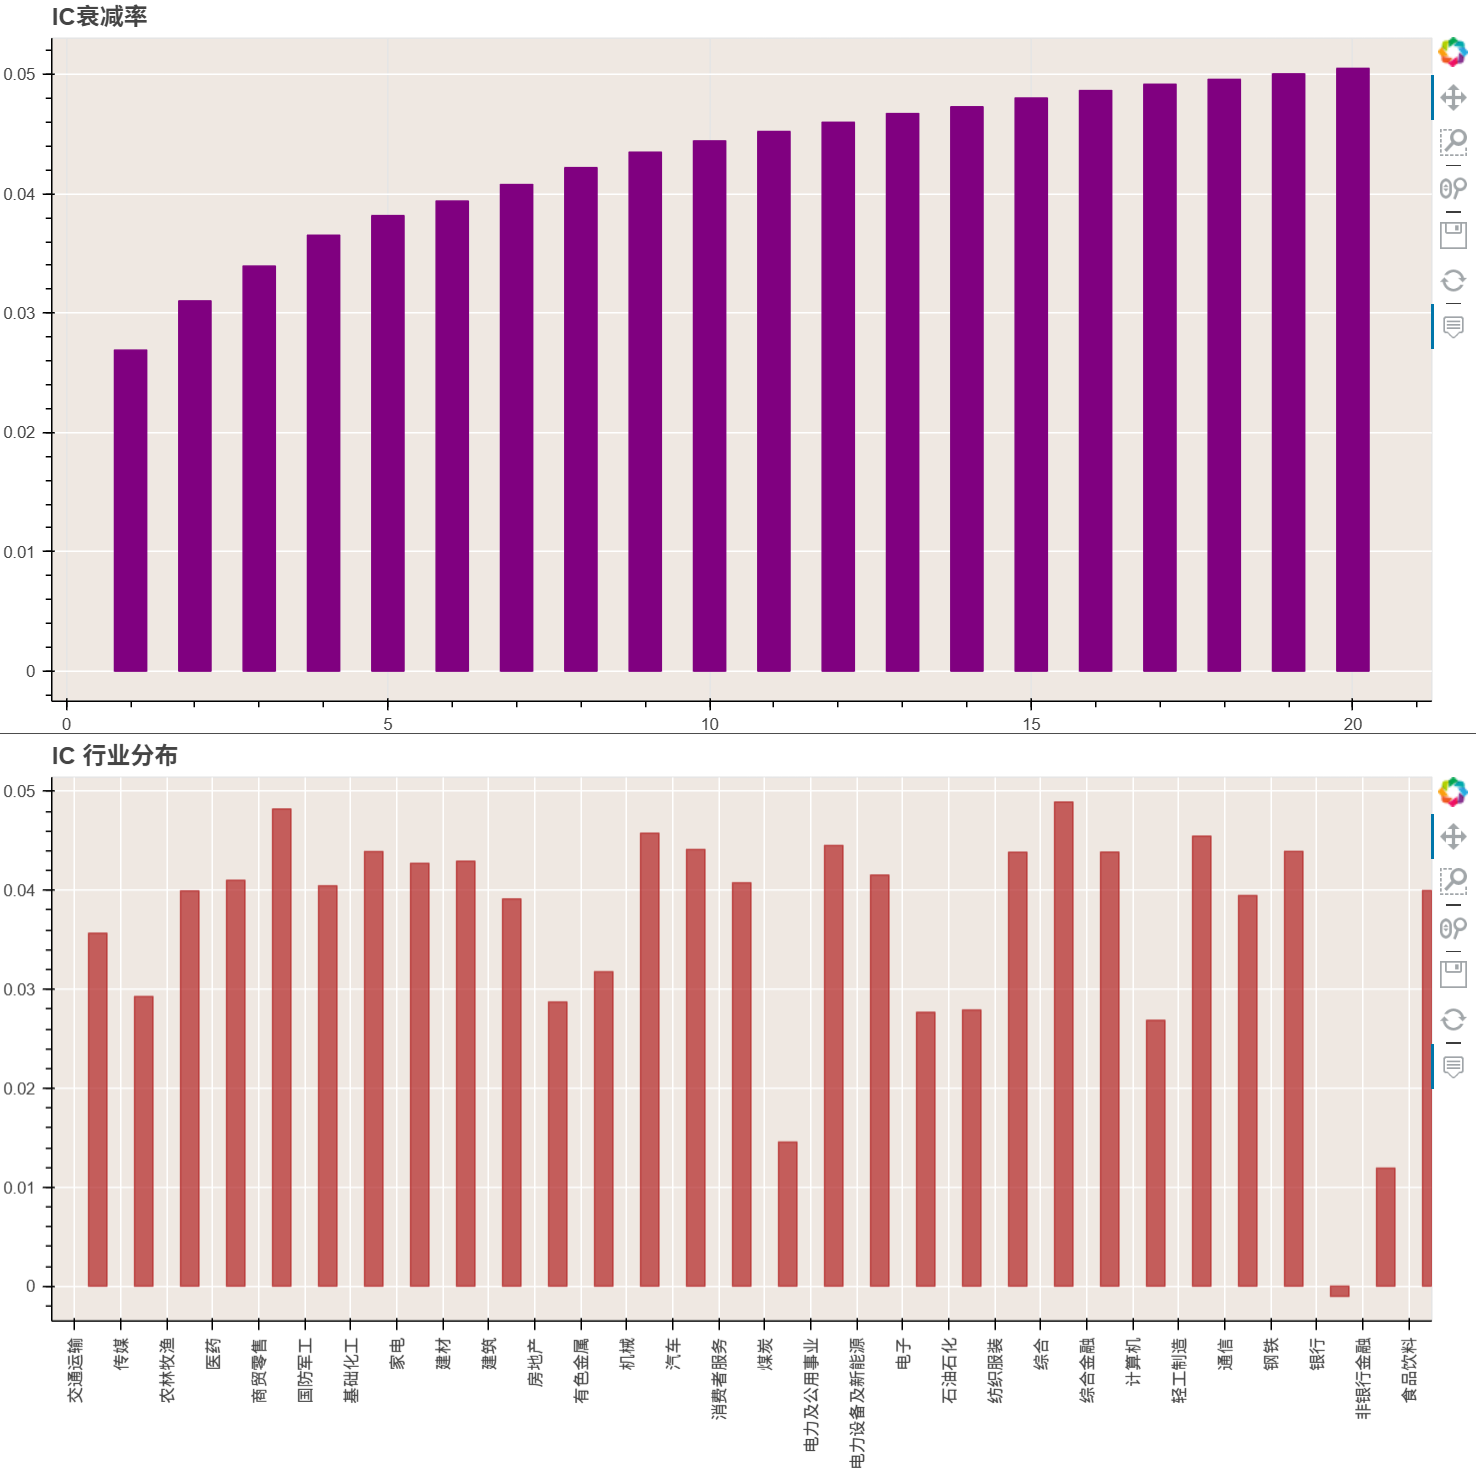

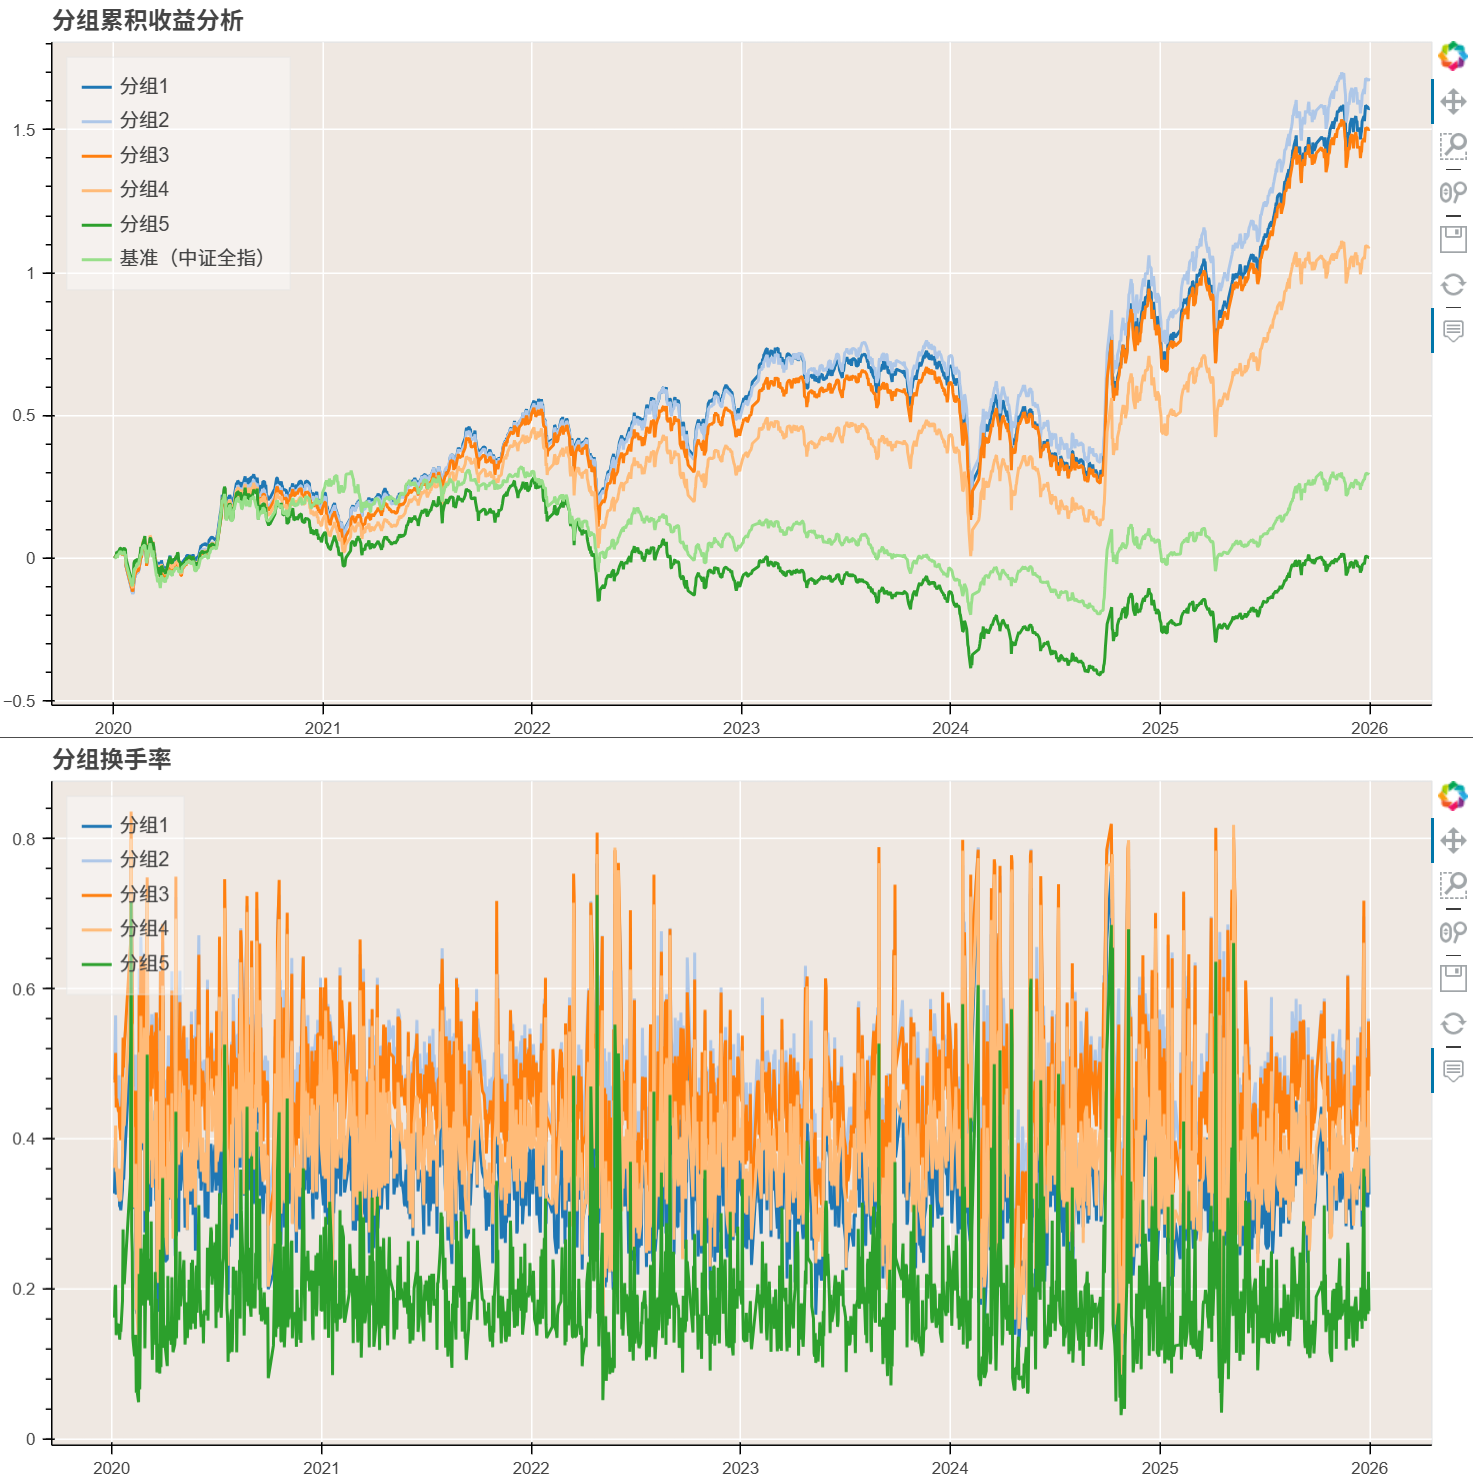

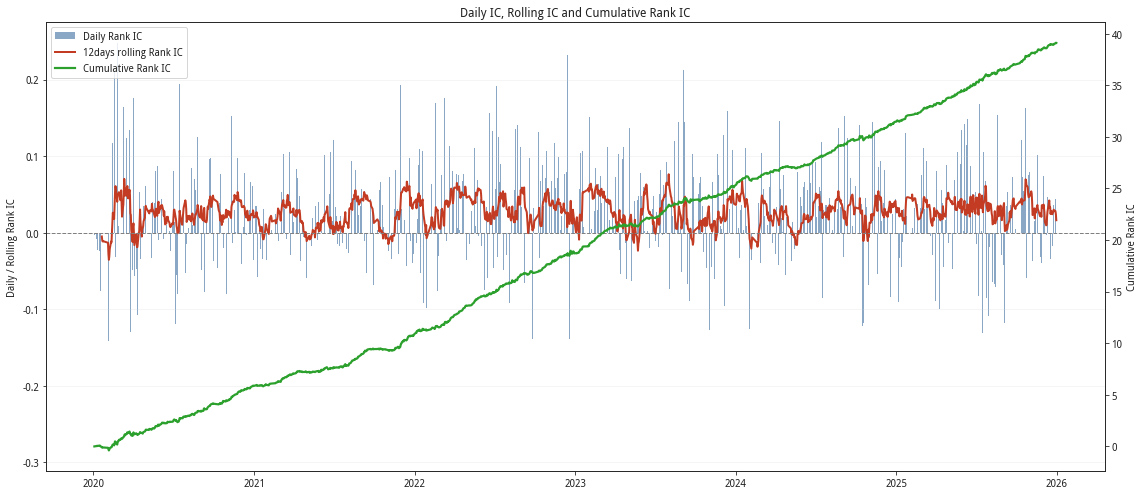

In [9]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_indus_abnd_beta.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()